# Etapa 10 — Métricas de áudio e de fala dos vídeos do Reddit

Inspirado no notebook `18_audio_metrics.ipynb` do repositório
[estermariaa/lei_felca](https://github.com/estermariaa/lei_felca), adaptado à nossa base.

**Diferença importante:** a etapa 6 apaga cada MP3 depois de transcrever, e baixar de novo
cerca de 284 h de áudio esbarra no bloqueio do YouTube. Por isso as métricas que dependem do
sinal (SNR, amplitude, zero-crossing rate, regiões de silêncio) **não foram calculadas**. As
métricas aqui saem da transcrição do Whisper e da API do YouTube, geradas por
`basemateus/videosDoReddit/scripts/10_metricas_audio.py`.

Perguntas:
1. Os blocos diferem em **duração** e **densidade de fala**? (vídeos falados × música/gameplay)
2. Que **ritmo** de fala predomina em cada bloco?
3. As métricas explicam as **transcrições ruins** (`low_content`, `repeticao_alta`, `idioma_suspeito`)?
4. Densidade de fala tem relação com **views**?

## Descrição das métricas

| Coluna | O que é | Como ler |
|---|---|---|
| `duracao_video_s` | duração do vídeo pela API | vídeos com mais de 1 h não foram transcritos |
| `fim_fala_s` | fim do último trecho com fala segundo o Whisper | vazio = nenhuma fala detectada |
| `cobertura_fala` | `fim_fala_s / duracao_video_s` (máx. 1) | **até onde vai a fala**, não a fração de tempo falado. Baixo = fala só no início (intro, trailer, gameplay) |
| `n_palavras`, `n_frases` | do texto limpo (etapa 9) | |
| `palavras_por_frase` | `n_palavras / n_frases` | valores enormes = texto sem pontuação (letra de música, alucinação) |
| `ppm_video` | palavras por minuto de vídeo | densidade de fala no vídeo inteiro |
| `ppm_fala` | palavras por minuto até o fim da fala | ritmo de quem fala |
| `ritmo` | faixas de `ppm_video` | `sem_fala`, `esparsa` (< 60), `moderada` (60–120), `normal` (120–180), `rapida` (> 180). Conversa em inglês fica em torno de 130–160 ppm |

**Atenção:** vídeos não ingleses passaram pela tradução do Whisper; as contagens são das palavras
em inglês. As comparações de ritmo usam **só a base recomendada em inglês original**.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# acha a raiz do repositório a partir de onde o notebook estiver aberto
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "basemateus").is_dir())
RESULTADOS = RAIZ / "basemateus" / "videosDoReddit" / "resultados"
GRAFICOS = RESULTADOS / "graficos"
GRAFICOS.mkdir(exist_ok=True)

df = pd.read_csv(RESULTADOS / "10_metricas_audio.csv")

BLOCOS = ["manosphere/ideologia", "autocuidado/estetica", "looksmaxxing", "fora do recorte"]
CORES = {"manosphere/ideologia": "#2a78d6", "autocuidado/estetica": "#eb6834",
         "looksmaxxing": "#1baf7a", "fora do recorte": "#8a8985"}   # fora do recorte em cinza: é a referência
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "font.size": 10})

base = df[df["base_recomendada"] & ~df["traduzido"]].copy()
print(f"Transcritos: {len(df)} | base recomendada: {int(df['base_recomendada'].sum())} "
      f"| base recomendada em inglês original: {len(base)}")
base["bloco"].value_counts().reindex(BLOCOS)

Transcritos: 1841 | base recomendada: 1637 | base recomendada em inglês original: 1410


bloco
manosphere/ideologia     186
autocuidado/estetica     113
looksmaxxing              29
fora do recorte         1082
Name: count, dtype: int64

## 1. Estatísticas descritivas por bloco (base recomendada, inglês original)

In [2]:
METRICAS = ["duracao_video_s", "cobertura_fala", "ppm_video", "ppm_fala", "palavras_por_frase"]
resumo = base.groupby("bloco")[METRICAS].agg(["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
resumo.columns = [f"{m}_{e}" for m, e in zip(resumo.columns.get_level_values(0), ["mediana", "q1", "q3"] * len(METRICAS))]
resumo = resumo.reindex(BLOCOS).round(1)
resumo.to_csv(RESULTADOS / "10_resumo_por_bloco.csv")
resumo

,duracao_video_s_mediana,duracao_video_s_q1,duracao_video_s_q3,cobertura_fala_mediana,cobertura_fala_q1,cobertura_fala_q3,ppm_video_mediana,ppm_video_q1,ppm_video_q3,ppm_fala_mediana,ppm_fala_q1,ppm_fala_q3,palavras_por_frase_mediana,palavras_por_frase_q1,palavras_por_frase_q3
bloco,,,,,,,,,,,,,,,
manosphere/ideologia,407.0,241.2,935.8,1.0,1.0,1.0,174.2,153.6,191.2,175.8,156.0,191.5,14.8,11.4,18.7
autocuidado/estetica,533.0,244.0,951.0,1.0,1.0,1.0,174.0,144.2,198.4,179.8,147.6,200.7,16.3,13.0,19.8
looksmaxxing,349.0,159.0,601.0,1.0,1.0,1.0,147.1,120.2,178.9,156.4,132.1,180.5,16.0,11.9,20.3
fora do recorte,302.5,152.0,754.2,1.0,1.0,1.0,145.6,98.3,175.4,149.9,105.5,179.2,14.1,8.7,19.3


## 2. Densidade de fala por bloco

Kruskal-Wallis entre os quatro blocos e, para cada bloco do recorte, Mann-Whitney contra
"fora do recorte" (que funciona como referência do que o Reddit compartilha em geral).

In [3]:
def compara(coluna):
    grupos = [base.loc[base["bloco"] == b, coluna].dropna() for b in BLOCOS]
    h, p = stats.kruskal(*grupos)
    linhas = []
    ref = grupos[-1]
    for b, g in zip(BLOCOS[:-1], grupos[:-1]):
        u, pu = stats.mannwhitneyu(g, ref, alternative="two-sided")
        linhas.append({"bloco": b, "n": len(g), "mediana": g.median(), "mediana_fora": ref.median(),
                       "p_mann_whitney": pu, "efeito_r": 2 * u / (len(g) * len(ref)) - 1})
    print(f"{coluna}: Kruskal-Wallis H = {h:.1f}, p = {p:.2g}")
    return pd.DataFrame(linhas).round(4)

testes = (pd.concat({c: compara(c) for c in ["ppm_video", "duracao_video_s", "cobertura_fala"]}, names=["metrica", None])
            .droplevel(1).reset_index())
testes.to_csv(RESULTADOS / "10_testes_por_bloco.csv", index=False)
testes

ppm_video: Kruskal-Wallis H = 91.7, p = 9.3e-20
duracao_video_s: Kruskal-Wallis H = 21.6, p = 8e-05
cobertura_fala: Kruskal-Wallis H = 19.6, p = 0.0002


,metrica,bloco,n,mediana,mediana_fora,p_mann_whitney,efeito_r
0,ppm_video,manosphere/ideologia,186,174.250,145.55,0.0000,0.3630
1,ppm_video,autocuidado/estetica,113,174.000,145.55,0.0000,0.3579
2,ppm_video,looksmaxxing,29,147.100,145.55,0.5501,0.0650
3,duracao_video_s,manosphere/ideologia,186,407.000,302.50,0.0009,0.1517
4,duracao_video_s,autocuidado/estetica,113,533.000,302.50,0.0004,0.2031
5,duracao_video_s,looksmaxxing,29,349.000,302.50,0.8622,-0.0189
6,cobertura_fala,manosphere/ideologia,186,0.996,0.99,0.0000,0.1866
7,cobertura_fala,autocuidado/estetica,113,0.995,0.99,0.0283,0.1250
8,cobertura_fala,looksmaxxing,29,0.991,0.99,0.7707,0.0316


`efeito_r` é a correlação rank-bisserial: positivo = o bloco tem valores maiores que "fora do recorte"; |r| ≈ 0,1 pequeno, 0,3 médio, 0,5 grande.

/tmp/ipykernel_793026/48102.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(dados, vert=False, widths=0.55, patch_artist=True, showfliers=False,
/tmp/ipykernel_793026/48102.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(dados, vert=False, widths=0.55, patch_artist=True, showfliers=False,


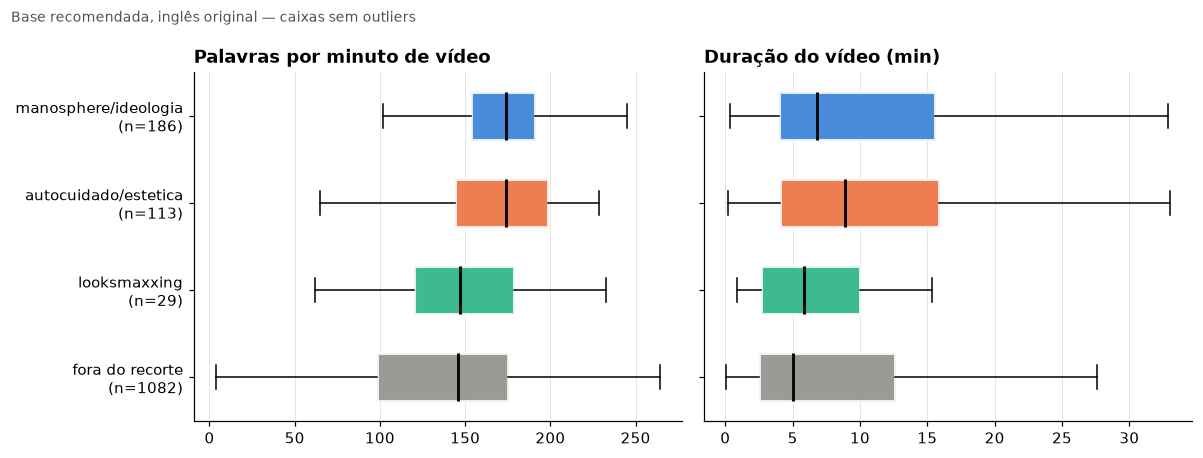

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, coluna, titulo in [(axes[0], "ppm_video", "Palavras por minuto de vídeo"),
                           (axes[1], "duracao_video_s", "Duração do vídeo (min)")]:
    dados = [base.loc[base["bloco"] == b, coluna].dropna() / (60 if coluna == "duracao_video_s" else 1) for b in BLOCOS]
    bp = ax.boxplot(dados, vert=False, widths=0.55, patch_artist=True, showfliers=False,
                    medianprops={"color": "#0b0b0b", "linewidth": 2})
    for caixa, b in zip(bp["boxes"], BLOCOS):
        caixa.set(facecolor=CORES[b], alpha=0.85, edgecolor="#fcfcfb", linewidth=2)
    ax.set_yticks(range(1, len(BLOCOS) + 1),
                  [f"{b}\n(n={len(d)})" for b, d in zip(BLOCOS, dados)])
    ax.invert_yaxis()
    ax.set_title(titulo, loc="left", fontweight="bold")
    ax.grid(axis="y", visible=False)
axes[1].set_yticklabels([])
fig.suptitle("Base recomendada, inglês original — caixas sem outliers", x=0.01, ha="left", color="#52514e", fontsize=9)
fig.tight_layout()
fig.savefig(GRAFICOS / "10_densidade_e_duracao_por_bloco.png", bbox_inches="tight")
plt.show()

## 3. Ritmo da fala por bloco

In [5]:
ORDEM_RITMO = ["sem_fala", "esparsa", "moderada", "normal", "rapida"]
ritmo = pd.crosstab(base["bloco"], base["ritmo"], normalize="index").reindex(index=BLOCOS, columns=ORDEM_RITMO).fillna(0)
chi2, p, gl, _ = stats.chi2_contingency(pd.crosstab(base["bloco"], base["ritmo"]))
print(f"Qui-quadrado bloco × ritmo: χ² = {chi2:.1f}, gl = {gl}, p = {p:.2g}")
(ritmo * 100).round(1)

Qui-quadrado bloco × ritmo: χ² = 83.7, gl = 9, p = 3e-14


ritmo,sem_fala,esparsa,moderada,normal,rapida
bloco,,,,,
manosphere/ideologia,0.0,2.2,6.5,54.3,37.1
autocuidado/estetica,0.0,0.9,9.7,46.0,43.4
looksmaxxing,0.0,6.9,17.2,51.7,24.1
fora do recorte,0.0,12.2,21.4,44.4,22.0


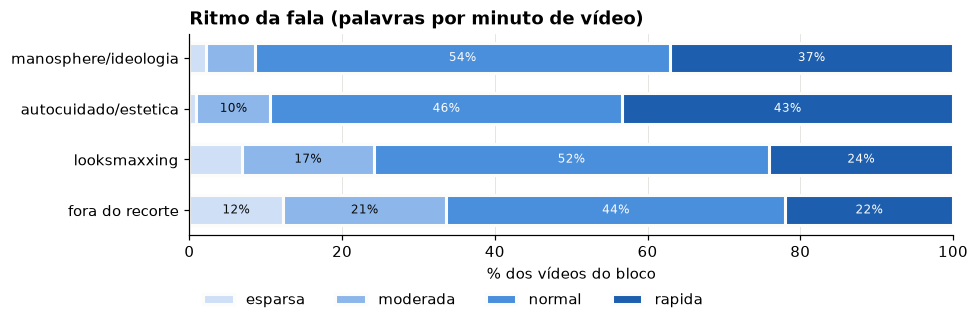

In [6]:
# sequencial de um só tom (azul claro -> escuro): ritmo é uma escala ordenada
TONS = {"esparsa": "#cfe0f6", "moderada": "#8db7ea", "normal": "#4a8fdc", "rapida": "#1d5fae"}
r = ritmo.drop(columns="sem_fala", errors="ignore")
fig, ax = plt.subplots(figsize=(9, 3.2))
esquerda = np.zeros(len(r))
for coluna in r.columns:
    ax.barh(r.index, r[coluna] * 100, left=esquerda, color=TONS[coluna], edgecolor="#fcfcfb", linewidth=2, label=coluna, height=0.6)
    for i, v in enumerate(r[coluna] * 100):
        if v >= 8:
            ax.text(esquerda[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8,
                    color="#0b0b0b" if coluna in ("esparsa", "moderada") else "#fcfcfb")
    esquerda += r[coluna].values * 100
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% dos vídeos do bloco")
ax.set_title("Ritmo da fala (palavras por minuto de vídeo)", loc="left", fontweight="bold")
ax.legend(ncol=4, frameon=False, loc="upper left", bbox_to_anchor=(0, -0.22))
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(GRAFICOS / "10_ritmo_por_bloco.png", bbox_inches="tight")
plt.show()

## 4. As métricas explicam as transcrições ruins?

Aqui entram **todos os 1.841 transcritos**, porque a pergunta é justamente sobre os que
saíram da base.

In [7]:
df["qualidade"] = np.select(
    [df["low_content"], df["repeticao_alta"], df["idioma_suspeito"]],
    ["low_content", "repeticao_alta", "idioma_suspeito"], default="ok")
qual = df.groupby("qualidade").agg(
    videos=("video_id", "size"),
    duracao_mediana_min=("duracao_video_s", lambda s: s.median() / 60),
    cobertura_mediana=("cobertura_fala", "median"),
    ppm_video_mediano=("ppm_video", "median"),
    palavras_por_frase_mediana=("palavras_por_frase", "median"),
).reindex(["ok", "low_content", "repeticao_alta", "idioma_suspeito"]).round(2)
qual

,videos,duracao_mediana_min,cobertura_mediana,ppm_video_mediano,palavras_por_frase_mediana
qualidade,,,,,
ok,1637,5.27,0.99,144.30,14.30
low_content,155,1.12,0.88,0.90,2.15
repeticao_alta,24,5.41,1.00,10.65,13.30
idioma_suspeito,25,4.42,0.98,29.10,10.00


In [8]:
# transcrições "ok" com pouca fala: candidatas a revisão (música, gameplay, trailer)
suspeitos = df[(df["qualidade"] == "ok") & ((df["ppm_video"] < 30) | (df["palavras_por_frase"] > 100))]
print(f"{len(suspeitos)} vídeos na base recomendada com menos de 30 ppm ou mais de 100 palavras por frase")
suspeitos.sort_values("ppm_video")[["bloco", "title", "idioma_original", "duracao_video_s",
                                    "n_palavras", "ppm_video", "palavras_por_frase"]].head(20)

214 vídeos na base recomendada com menos de 30 ppm ou mais de 100 palavras por frase


,bloco,title,idioma_original,duracao_video_s,n_palavras,ppm_video,palavras_por_frase
1056,fora do recorte,Legend of Zelda Breath of the Wild on Cemu on ...,ja,2713,73,1.6,9.1
1449,fora do recorte,Neo vs Smith Clones [Part 2] | The Matrix Relo...,en,236,15,3.8,5.0
1495,fora do recorte,"Apotheosis, An Elder Scrolls V Expansion Mod -...",ja,172,11,3.8,5.5
1585,looksmaxxing,✧･ﾟ*₊˚༄ true beauty: ˚✩ ༉,en,672,42,3.8,6.0
887,fora do recorte,Paathira Kaalam - Video Song | Kurup | Dulquer...,ta,230,15,3.9,7.5
1789,fora do recorte,SpaceCamp OST - In Orbit - UAP (Unidentified A...,en,193,15,4.7,7.5
1592,looksmaxxing,overnight potion ● grants any wish 1000x times...,en,151,17,6.8,8.5
510,fora do recorte,First Contact with Thargoids in Elite Dangerous,en,148,18,7.3,2.2
826,fora do recorte,VARIOUS DAYLIFE | Announcement Trailer,en,109,15,8.3,15.0
428,fora do recorte,The Jimi Hendrix Experience - Voodoo Child (Sl...,en,375,52,8.3,52.0


## 5. Densidade de fala × views

In [9]:
linhas = []
for b in BLOCOS:
    g = base[base["bloco"] == b].dropna(subset=["ppm_video", "view_count"])
    rho, p = stats.spearmanr(g["ppm_video"], g["view_count"])
    rho_d, p_d = stats.spearmanr(g["duracao_video_s"], g["view_count"])
    linhas.append({"bloco": b, "n": len(g), "rho_ppm_views": rho, "p_ppm": p,
                   "rho_duracao_views": rho_d, "p_duracao": p_d})
correl = pd.DataFrame(linhas).round(3)
correl.to_csv(RESULTADOS / "10_correlacao_views.csv", index=False)
correl

,bloco,n,rho_ppm_views,p_ppm,rho_duracao_views,p_duracao
0,manosphere/ideologia,186,-0.018,0.804,-0.068,0.356
1,autocuidado/estetica,113,-0.151,0.110,-0.029,0.760
2,looksmaxxing,29,-0.381,0.042,0.244,0.202
3,fora do recorte,1082,-0.170,0.000,-0.017,0.567


## 6. Observações para o relatório

Resultados da primeira rodada (nov/2026; base recomendada em inglês original, 1.410 vídeos):

- **Manosphere e autocuidado são vídeos de fala densa.** Mediana de 174 palavras por minuto
  nos dois, contra 146 em "fora do recorte" (Mann-Whitney p < 0,001, efeito r ≈ 0,36, médio).
  Looksmaxxing (147 ppm) não difere de "fora do recorte" (p = 0,55; só 29 vídeos).
- **Ritmo:** 91% dos vídeos de manosphere e 89% dos de autocuidado têm fala normal ou rápida
  (≥ 120 ppm), contra 66% em "fora do recorte", que tem mais música, trailers e gameplay
  (χ² = 83,7; p < 0,001).
- **Duração:** autocuidado (mediana de 8,9 min) e manosphere (6,8 min) são mais longos que
  "fora do recorte" (5 min), com efeito pequeno (r ≈ 0,15–0,20).
- **`cobertura_fala` discrimina pouco:** a mediana fica perto de 1 em todos os blocos.
- **Os filtros de qualidade batem com as métricas:** `low_content` tem mediana de 0,9 ppm,
  `repeticao_alta` 10,7 e `idioma_suspeito` 29,1, contra 144 nos vídeos "ok".
- **Ainda há ruído na base recomendada:** 214 vídeos "ok" têm menos de 30 ppm ou mais de
  100 palavras por frase, quase todos trailers, músicas e gameplay de "fora do recorte".
  Vale considerar `ppm_video < 30` como filtro extra para análises de discurso.
- **Views:** densidade de fala e duração praticamente não se relacionam com views nos blocos
  do recorte (|ρ| < 0,16, p > 0,1), exceto looksmaxxing (ρ = −0,38, p = 0,04, n = 29, frágil).

**Limitações:** sem as métricas de sinal (SNR, silêncio, ZCR), porque os áudios foram apagados
depois da transcrição; `cobertura_fala` mede até onde a fala vai, não quanto do tempo é falado;
contagens dos vídeos traduzidos são da tradução.